# The nonlocal permittivity of the rod lattice, and how much of it is a permeability

Notebook 01 said what to compute: the single tensor $\varepsilon(\omega,\mathbf k)$ of the lattice, off the dispersion curve, and its expansion in $\mathbf k$. This notebook computes it exactly for the square lattice of rods of notebook 02, by driving the lattice with an external current of arbitrary wavevector (Silveirinha's source-driven homogenization), and reads off the second-order coefficients.

## What this notebook shows

- $\varepsilon(\omega,\mathbf k)$ from multiple scattering with a distributed source, checked against a plane-wave solution, the static mixing formulas, and the Bloch modes of notebook 02, which it reproduces through $k^2=k_0^2\varepsilon^T(\omega,\mathbf k)$.
- TE: the three second-order coefficients $\tau$, $\lambda$, $\delta$ of notebook 01. Only $\tau$ is resonant and only $\tau$ grows with the rod permittivity, with the slope a current loop gives. $\lambda$ and $\delta$ are a background fixed by the geometry.
- The permeability from $\tau$, compared with the O'Brien-Pendry formula, and the apparent permeabilities along $\Gamma X$ and $\Gamma M$, which differ by an amount that is negligible at resonance and comparable to $\mu-1$ far below it.
- How far the second-order description reaches: Bloch wavenumbers from the local parameters against the exact ones, and the index anisotropy that $\delta$ predicts.
- TM: the second-order coefficient is isotropic by symmetry and vanishes at low frequency, although each rod has a magnetic-dipole moment. A Bloch mode that the nonlocal permittivity cannot see at all.

## Conventions

As in notebook 02: $e^{-i\omega t}$, lengths in units of the period $a$, $f=a/\lambda_0$, $\varepsilon_0=\mu_0=c=1$, rod radius $R=0.3$, TM is $\mathbf E$ along the rods and TE is $\mathbf H$ along the rods. $\varphi$ is the angle of $\mathbf k$ from a lattice axis; $\Gamma X$ is $\varphi=0$ and $\Gamma M$ is $\varphi=\pi/4$.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/spatial_dispersion (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # rodlattice.py sits next to this notebook
import rodlattice as rl
from scipy.special import jv, j1

TWO_PI = 2 * np.pi
R = 0.3
FILL = np.pi * R**2
J0_ZERO = 2.404825557695773

## 1. Driving the lattice off shell

Free Bloch waves sample $\varepsilon(\omega,\mathbf k)$ only on the dispersion curve. To get it elsewhere, add an external current $\mathbf J_0e^{i\mathbf k\cdot\mathbf r}$ that fills all space, rods included, with $\mathbf k$ chosen at will. The response has the Bloch vector $\mathbf k$, and the macroscopic fields are its $e^{i\mathbf k\cdot\mathbf r}$ Fourier components,

$$\langle\mathbf E\rangle=\frac1A\int_{\rm cell}\mathbf E\,e^{-i\mathbf k\cdot\mathbf r}\,d^2r,\qquad\langle\mathbf P\rangle=\frac{\varepsilon_r-1}{A}\int_{\rm rod}\mathbf E\,e^{-i\mathbf k\cdot\mathbf r}\,d^2r,\qquad\langle\mathbf P\rangle=\big[\varepsilon(\omega,\mathbf k)-1\big]\langle\mathbf E\rangle .$$

Averaging Maxwell's equations with the same weight is exact and gives $\mathbf k\times(\mathbf k\times\langle\mathbf E\rangle)+k_0^2\langle\mathbf E\rangle+k_0^2\langle\mathbf P\rangle=-ik_0\mathbf J_0$, so $\langle\mathbf E\rangle$ follows from $\langle\mathbf P\rangle$, and a free mode ($\mathbf J_0=0$, $\langle\mathbf E\rangle\neq0$) exists where $k^2=k_0^2\varepsilon^T(\omega,\mathbf k)$.

**The microscopic problem.** In each homogeneous region the driven Helmholtz equation has a plane-wave particular solution: for TM, $E_z=e\,e^{i\mathbf k\cdot\mathbf r}$ with $e=ik_0J_0/(k^2-k_0^2\varepsilon)$; for TE, $H_z=h\,e^{i\mathbf k\cdot\mathbf r}$ with $h=i(\mathbf k\times\mathbf J_0)_z/(k^2-k_0^2\varepsilon)$. The two particular solutions (inside and outside a rod) do not match at the rod surface, and the mismatch is what the cylindrical waves have to repair. Expanding $e^{i\mathbf k\cdot\mathbf r}=\sum_li^le^{-il\varphi_k}J_l(kr)e^{il\varphi}$ and matching $u$ and $q\,\partial_ru$ (for TE the second condition is continuity of $(\partial_rH_z+J_\varphi)/\varepsilon$, so the source itself appears in it) gives

$$b_l=t_la_l+\sigma_l,\qquad a_l=\sum_mG_{l-m}b_m\quad\Longrightarrow\quad(I-TG)\,b=\sigma,$$

the multiple-scattering system of notebook 02 with a right-hand side. The interior field then gives $\langle\mathbf P\rangle$ by quadrature over the rod. `rodlattice.driven` implements this for real or complex $\mathbf k$; for TE it uses one source along $\mathbf k$ and one across it and returns the $2\times2$ in-plane tensor.

## 2. Checks

In [3]:
def pw_driven_tm(k0, kvec, eps, nmax=14):
    """eps_zz(w, k) from a plane-wave solution of (|k + G|^2 - k0^2 eps) E = i k0 J."""
    g = TWO_PI * np.arange(-nmax, nmax + 1)
    GX, GY = [v.ravel() for v in np.meshgrid(g, g, indexing="ij")]
    Q = np.hypot(GX[:, None] - GX[None, :], GY[:, None] - GY[None, :])
    S = np.where(Q > 1e-12, TWO_PI * R * j1(Q * R) / np.where(Q > 1e-12, Q, 1.0), FILL)
    A = np.diag((kvec[0] + GX) ** 2 + (kvec[1] + GY) ** 2) - k0**2 * (np.eye(len(GX)) + (eps - 1) * S)
    i0 = np.argmin(np.hypot(GX, GY))
    rhs = np.zeros(len(GX), complex); rhs[i0] = 1j * k0
    E = np.linalg.solve(A, rhs)
    return 1 + (eps - 1) * (S[i0] @ E) / E[i0]


def eps_parts(pol, k0, kap, phi, eps, M=4):
    """Components of eps(w, k) for k = kap (cos phi, sin phi): [zz] for TM; [across-across, along-along, across-along] for TE."""
    kh = np.array([np.cos(phi), np.sin(phi)])
    e = rl.driven(k0, kap * kh, R, eps, pol, M=M)[0]
    if pol == "TM":
        return np.array([e])
    th = np.array([-kh[1], kh[0]])
    return np.array([th @ e @ th, kh @ e @ kh, th @ e @ kh])


print("(a) TM against plane waves (441 -> 841 waves), including a lossy rod")
worst = 0.0
for eps, f, kv in [(12.0, 0.25, (0.8, 0.8)), (12.0, 0.32, (2.5, 0.3)), (12 + 0.5j, 0.33, (0.4, 0.0)), (100.0, 0.05, (0.9, 0.2))]:
    k0 = TWO_PI * f
    ms, pw = rl.driven(k0, kv, R, eps, "TM")[0], pw_driven_tm(k0, kv, eps)
    worst = max(worst, abs(ms / pw - 1))
    print(f"    eps_r = {eps}, f = {f}, k = {kv}: MS {ms:.6f}   PW {pw:.6f}")
check("(a) TM eps_zz(w, k): multiple scattering vs plane waves (relative)", worst, 1e-3)

print("(b) static limit, f = 1e-3, k = (2e-3, 1e-3)")
k0 = TWO_PI * 1e-3
for eps in (12.0, 100.0):
    b = (eps - 1) / (eps + 1)
    rayleigh = 1 + 2 * FILL / (1 / b - FILL - 0.305827 * b * FILL**4 - 0.013362 * b * FILL**8)
    check(f"(b) TM, eps_r = {eps:g}: area average 1 + f (eps_r - 1) (relative)", rl.driven(k0, (2e-3, 1e-3), R, eps, "TM")[0].real / (1 + FILL * (eps - 1)) - 1, 1e-4)
    e_te = rl.driven(k0, (2e-3, 1e-3), R, eps, "TE", M=6)[0]
    check(f"(b) TE, eps_r = {eps:g}: Rayleigh's series for the square array", e_te[0, 0].real, 2e-5, rayleigh)
    check(f"(b) TE, eps_r = {eps:g}: isotropic at k -> 0", abs(e_te[0, 0] - e_te[1, 1]) + abs(e_te[0, 1]), 1e-5)

print("(c) free Bloch modes satisfy k^2 = k0^2 eps_T(w, k)")
worst, missed = 0.0, []
for pol, kB in [("TM", (1.0, 0.0)), ("TM", (2.0, 2.0)), ("TE", (1.0, 0.0)), ("TE", (2.0, 2.0))]:
    phi, kap = np.arctan2(kB[1], kB[0]), np.hypot(*kB)
    modes = rl.bloch_frequencies(kB, R, 12.0, pol, M=4, fmax=0.405)
    for fm in modes:
        resid = (TWO_PI * fm) ** 2 * eps_parts(pol, TWO_PI * fm, kap, phi, 12.0)[0] - kap**2
        print(f"    {pol}, kB = {kB}, mode at f = {fm:.5f}: k0^2 eps_T - k^2 = {resid.real:+.2e}")
        if abs(resid) < 1e-3:
            worst = max(worst, abs(resid))
        else:
            missed.append((pol, kB, fm))
check("(c) residual at the modes that the driven response sees (the system is singular there, which limits the accuracy)", worst, 1e-6)
print(f"    modes with a residual above 1e-3: {missed}")
assert len(missed) == 2 and all(m[0] == "TM" for m in missed)

print("(d) convergence in the multipole order, and symmetries")
k0 = TWO_PI * 0.30
e4, e6 = (rl.driven(k0, (0.6, 0.2), R, 12.0, "TE", M=M)[0] for M in (4, 6))
check("(d) TE tensor, M = 4 against M = 6", np.abs(e4 - e6).max(), 1e-5)
check("(d) lossless rods, real k: the tensor is real symmetric", np.abs(e6.imag).max() + abs(e6[0, 1] - e6[1, 0]), 1e-9)
check("(d) eps(w, k) = eps(w, -k)", np.abs(e6 - rl.driven(k0, (-0.6, -0.2), R, 12.0, "TE", M=6)[0]).max(), 1e-9)

(a) TM against plane waves (441 -> 841 waves), including a lossy rod
    eps_r = 12.0, f = 0.25, k = (0.8, 0.8): MS 6.340673+0.000000j   PW 6.340580+0.000000j
    eps_r = 12.0, f = 0.32, k = (2.5, 0.3): MS 1.949472+0.000000j   PW 1.949139+0.000000j
    eps_r = (12+0.5j), f = 0.33, k = (0.4, 0.0): MS 14.183770+3.106131j   PW 14.183333+3.105959j
    eps_r = 100.0, f = 0.05, k = (0.9, 0.2): MS 33.211783+0.000000j   PW 33.211573+0.000000j
PASS  (a) TM eps_zz(w, k): multiple scattering vs plane waves (relative): got 0.000170696, target 0, |diff| 1.71e-04 <= 1e-03
(b) static limit, f = 1e-3, k = (2e-3, 1e-3)
PASS  (b) TM, eps_r = 12: area average 1 + f (eps_r - 1) (relative): got 4.21163e-06, target 0, |diff| 4.21e-06 <= 1e-04
PASS  (b) TE, eps_r = 12: Rayleigh's series for the square array: got 1.63012, target 1.63012, |diff| 9.97e-08 <= 2e-05
PASS  (b) TE, eps_r = 12: isotropic at k -> 0: got 1.14911e-07, target 0, |diff| 1.15e-07 <= 1e-05
PASS  (b) TM, eps_r = 100: area average 1 + f (eps

    TM, kB = (1.0, 0.0), mode at f = 0.07746: k0^2 eps_T - k^2 = -5.59e-08
    TM, kB = (1.0, 0.0), mode at f = 0.37920: k0^2 eps_T - k^2 = +5.89e-11
    TM, kB = (1.0, 0.0), mode at f = 0.40291: k0^2 eps_T - k^2 = +5.21e+01
    TM, kB = (2.0, 2.0), mode at f = 0.19443: k0^2 eps_T - k^2 = -2.05e-11
    TM, kB = (2.0, 2.0), mode at f = 0.34999: k0^2 eps_T - k^2 = +1.51e-12
    TM, kB = (2.0, 2.0), mode at f = 0.36344: k0^2 eps_T - k^2 = +4.68e+00


    TE, kB = (1.0, 0.0), mode at f = 0.12327: k0^2 eps_T - k^2 = -5.23e-14
    TE, kB = (1.0, 0.0), mode at f = 0.39875: k0^2 eps_T - k^2 = -5.10e-12
    TE, kB = (2.0, 2.0), mode at f = 0.31595: k0^2 eps_T - k^2 = +5.08e-13
PASS  (c) residual at the modes that the driven response sees (the system is singular there, which limits the accuracy): got 5.59018e-08, target 0, |diff| 5.59e-08 <= 1e-06
    modes with a residual above 1e-3: [('TM', (1.0, 0.0), np.float64(0.4029130823781644)), ('TM', (2.0, 2.0), np.float64(0.36344305979544017))]
(d) convergence in the multipole order, and symmetries
PASS  (d) TE tensor, M = 4 against M = 6: got 1.23019e-06, target 0, |diff| 1.23e-06 <= 1e-05
PASS  (d) lossless rods, real k: the tensor is real symmetric: got 1.9472e-15, target 0, |diff| 1.95e-15 <= 1e-09
PASS  (d) eps(w, k) = eps(w, -k): got 1.38362e-15, target 0, |diff| 1.38e-15 <= 1e-09


Check (c) deserves a second look. Every TE mode satisfies the condition. Among the TM modes there are two that do not, one for each direction of $\mathbf k$: the lattice has a Bloch mode there and $k^2-k_0^2\varepsilon_{zz}$ is far from zero. Section 6 returns to them.

## 3. TE: the three second-order coefficients

For lossless rods and frequencies below the first diffraction threshold $\varepsilon(\omega,\mathbf k)$ is analytic and even in $\mathbf k$ near $\mathbf k=0$. Along a fixed direction write $\mathbf k=\kappa(\cos\varphi,\sin\varphi)$ with complex $\kappa$; the Taylor coefficients in $\kappa$ are Cauchy integrals over a circle $|\kappa|=\rho$, evaluated with the trapezoid rule, which is spectrally accurate and avoids finite differences. From the coefficients of $\kappa^2$ across and along $\mathbf k$ on $\Gamma X$ and $\Gamma M$, notebook 01 gives

$$\tau=\tfrac12\big(c^T_X+c^T_M\big),\qquad\delta=\tfrac12\big(c^T_M-c^T_X\big),\qquad\lambda=\tfrac12\big(c^L_X+c^L_M\big),$$

with the redundancy $c^T_X+c^L_X=c^T_M+c^L_M$ as a check.

PASS  coefficients do not depend on the radius of the circle (tau, relative): got -7.21645e-15, target 0, |diff| 7.22e-15 <= 1e-08
PASS  odd orders vanish: got 7.10128e-14, target 0, |diff| 7.10e-14 <= 1e-10
PASS  coefficients are real: got 2.15877e-15, target 0, |diff| 2.16e-15 <= 1e-10
PASS  redundancy c_T + c_L equal on GX and GM: got 4.94049e-15, target 0, |diff| 4.94e-15 <= 1e-10


coefficients on 156 frequencies: 4 s


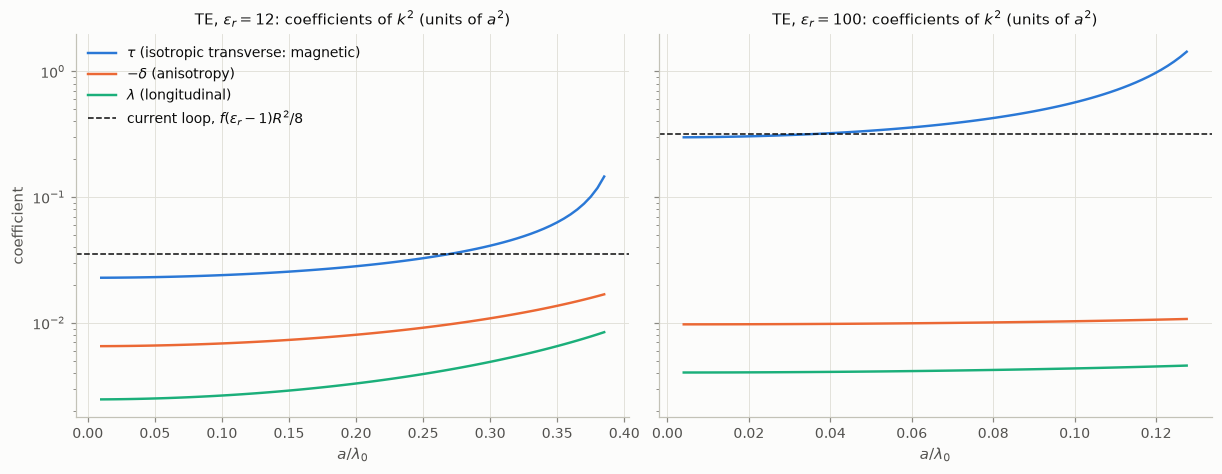

          f      tau       delta      lambda    |delta|/tau
eps_r=   12 0.0100   0.02285   -0.00653    0.00246    0.2857
eps_r=   12 0.2000   0.02821   -0.00805    0.00330    0.2852
eps_r=   12 0.3850   0.14579   -0.01687    0.00843    0.1157
eps_r=  100 0.0040   0.29909   -0.00973    0.00403    0.0325
eps_r=  100 0.0665   0.37563   -0.00997    0.00416    0.0265
eps_r=  100 0.1275   1.43307   -0.01074    0.00458    0.0075
eps_r = 12: over the range tau grows by a factor 6, delta by 2.58, lambda by 3.42
eps_r = 100: over the range tau grows by a factor 5, delta by 1.10, lambda by 1.14
PASS  eps_r = 100: delta changes by less than 15 percent over the range: got 1.10331, target 1, |diff| 1.03e-01 <= 1e-01
PASS  eps_r = 100: lambda changes by less than 15 percent over the range: got 1.13523, target 1, |diff| 1.35e-01 <= 1e-01
PASS  delta has the same sign and a similar size for both permittivities (ratio at the lowest frequency): got 1.49099, target 1.5, |diff| 9.01e-03 <= 5e-01
eps_r = 12

In [4]:
def taylor(fun, rho, n=16, orders=(0, 1, 2, 3, 4)):
    """Taylor coefficients at kappa = 0 of an analytic function, from n samples on the circle |kappa| = rho."""
    th = (np.arange(n) + 0.5) * TWO_PI / n
    vals = np.array([fun(rho * np.exp(1j * t)) for t in th])
    return np.array([(vals * np.exp(-1j * m * th)[:, None]).mean(axis=0) / rho**m for m in orders])


def te_coefficients(f, eps, rho=0.2, M=4):
    """eps_t(w), tau, delta, lambda and the two fourth-order transverse coefficients of the TE tensor at frequency f."""
    k0 = TWO_PI * f
    cX = taylor(lambda kap: eps_parts("TE", k0, kap, 0.0, eps, M), rho)
    cM = taylor(lambda kap: eps_parts("TE", k0, kap, np.pi / 4, eps, M), rho)
    out = dict(eps=cX[0, 0].real, tau=0.5 * (cX[2, 0] + cM[2, 0]).real, delta=0.5 * (cM[2, 0] - cX[2, 0]).real,
               lam=0.5 * (cX[2, 1] + cM[2, 1]).real, c4X=cX[4, 0].real, c4M=cM[4, 0].real,
               trace=((cX[2, 0] + cX[2, 1]) - (cM[2, 0] + cM[2, 1])).real,
               odd=max(np.abs(cX[1]).max(), np.abs(cX[3]).max(), np.abs(cM[1]).max()), imag=np.abs(cX[[0, 2]].imag).max())
    return out


c1, c2 = te_coefficients(0.25, 12.0, rho=0.15), te_coefficients(0.25, 12.0, rho=0.4)
check("coefficients do not depend on the radius of the circle (tau, relative)", c1["tau"] / c2["tau"] - 1, 1e-8)
check("odd orders vanish", c1["odd"], 1e-10)
check("coefficients are real", c1["imag"], 1e-10)
check("redundancy c_T + c_L equal on GX and GM", c1["trace"], 1e-10)

t0 = time.perf_counter()
F12 = np.linspace(0.01, 0.385, 76)
F100 = np.linspace(0.004, 0.1275, 80)
co12 = [te_coefficients(f, 12.0) for f in F12]
co100 = [te_coefficients(f, 100.0, rho=0.1) for f in F100]
print(f"coefficients on {len(F12) + len(F100)} frequencies: {time.perf_counter() - t0:.0f} s")
get = lambda co, key: np.array([c[key] for c in co])

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, F, co, eps in ((axs[0], F12, co12, 12.0), (axs[1], F100, co100, 100.0)):
    ax.semilogy(F, get(co, "tau"), color=CAT[0], label=r"$\tau$ (isotropic transverse: magnetic)")
    ax.semilogy(F, -get(co, "delta"), color=CAT[1], label=r"$-\delta$ (anisotropy)")
    ax.semilogy(F, get(co, "lam"), color=CAT[2], label=r"$\lambda$ (longitudinal)")
    ax.axhline(FILL * (eps - 1) * R**2 / 8, color=INK, ls="--", lw=1, label=r"current loop, $f(\varepsilon_r-1)R^2/8$")
    ax.set(xlabel=r"$a/\lambda_0$", title=rf"TE, $\varepsilon_r={eps:g}$: coefficients of $k^2$ (units of $a^2$)")
axs[0].set_ylabel("coefficient"); axs[0].legend(loc="upper left")
plt.show()

print("          f      tau       delta      lambda    |delta|/tau")
for F, co, eps in ((F12, co12, 12.0), (F100, co100, 100.0)):
    for i in (0, len(F) // 2, len(F) - 1):
        c = co[i]
        print(f"eps_r={eps:5g} {F[i]:6.4f} {c['tau']:9.5f} {c['delta']:10.5f} {c['lam']:10.5f} {abs(c['delta']) / c['tau']:9.4f}")
growth = {}
for F, co, eps in ((F12, co12, 12.0), (F100, co100, 100.0)):
    d, l, t = get(co, "delta"), get(co, "lam"), get(co, "tau")
    print(f"eps_r = {eps:g}: over the range tau grows by a factor {t[-1] / t[0]:.0f}, delta by {d[-1] / d[0]:.2f}, lambda by {l[-1] / l[0]:.2f}")
    growth[eps] = (t[-1] / t[0], d[-1] / d[0], l[-1] / l[0])
check("eps_r = 100: delta changes by less than 15 percent over the range", growth[100.0][1], 0.15, 1.0)
check("eps_r = 100: lambda changes by less than 15 percent over the range", growth[100.0][2], 0.15, 1.0)
assert growth[100.0][0] > 4 and growth[12.0][0] > growth[12.0][2] > 1
check("delta has the same sign and a similar size for both permittivities (ratio at the lowest frequency)", co100[0]["delta"] / co12[0]["delta"], 0.5, 1.5)
# through the pole of tau (the zero of mu) at eps_r = 12, the other two coefficients are smooth
below, above = te_coefficients(0.398, 12.0, rho=0.05), te_coefficients(0.405, 12.0, rho=0.05)
print(f"eps_r = 12 across the pole of tau: tau = {below['tau']:.2f} -> {above['tau']:.2f}, delta = {below['delta']:.4f} -> {above['delta']:.4f}, lambda = {below['lam']:.4f} -> {above['lam']:.4f}")
assert below["tau"] > 0.5 and above["tau"] < -0.5
check("delta is continuous across the pole of tau (relative change)", above["delta"] / below["delta"] - 1, 0.1)
check("lambda is continuous across the pole of tau (relative change)", above["lam"] / below["lam"] - 1, 0.1)

The division of labor is clean for $\varepsilon_r=100$: $\tau$ rises steeply toward the resonance while $\delta$ and $\lambda$ change by about a tenth over the same range. For $\varepsilon_r=12$ the resonance sits at $a/\lambda_0\approx0.4$, where nothing is quasi-static, and $\delta$ and $\lambda$ grow as well, by a factor of about three; but they do so smoothly, and they pass through the pole of $\tau$ (the zero of $\mu$) without noticing it. Between the two permittivities $\tau$ scales by more than ten at low frequency while $\delta$ and $\lambda$ change by half. In the terms of notebook 01, the resonant part of the second-order spatial dispersion is the one coefficient that is a permeability, and the other two are a background set mostly by the geometry.

**Where $\tau$ comes from.** At low frequency $H_z$ is uniform across the cell, Faraday's law gives an azimuthal field $E_\varphi=i\omega Br/2$ in the rod, and the polarization current $-i\omega(\varepsilon_r-1)E_\varphi$ is a loop with magnetic moment $\omega^2(\varepsilon_r-1)B\,\pi R^4/8$ per unit length. Divided by the cell area this is a magnetization $M=k_0^2\,\tau_{\rm loop}B$ with

$$\tau_{\rm loop}=\frac{f(\varepsilon_r-1)R^2}{8},$$

the dashed line. The static value of $\tau$ lies below it by a constant. The next cell varies the rod permittivity at a frequency low enough to be static for all of them and fits the dependence.

static coefficients (f = 0.001):
  eps_r      tau        tau - tau_loop     delta       lambda
      4     0.00274       -0.00681      -0.00274     0.00082
     12     0.02284       -0.01215      -0.00653     0.00246
     30     0.07760       -0.01464      -0.00855     0.00344
    100     0.29889       -0.01602      -0.00973     0.00403
    300     0.93475       -0.01633      -0.01011     0.00422
   1000     3.16254       -0.01514      -0.01024     0.00429
PASS  slope of tau against eps_r at large eps_r is the loop value f R^2 / 8: got 0.00318256, target 0.00318086, |diff| 1.70e-06 <= 1e-05
PASS  the non-magnetic part of tau saturates (change from eps_r = 100 to 1000): got 0.000878492, target 0, |diff| 8.78e-04 <= 2e-03
PASS  delta saturates (change from eps_r = 100 to 1000): got -0.000504214, target 0, |diff| 5.04e-04 <= 2e-03
Landau-Lifshitz ratio, loop coefficient over the largest other second-order coefficient:
   eps_r = 4: 1.4   eps_r = 12: 2.9   eps_r = 30: 6.3   eps_r = 100: 19

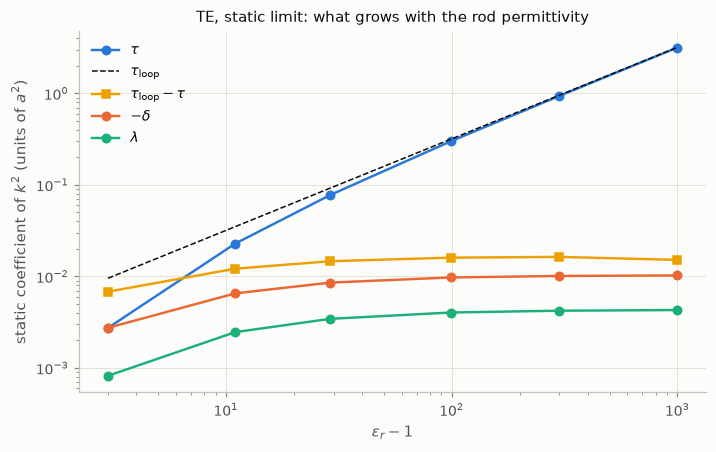

In [5]:
eps_list = np.array([4.0, 12.0, 30.0, 100.0, 300.0, 1000.0])
stat = [te_coefficients(1e-3, e, rho=0.05, M=5) for e in eps_list]
tau0, delta0, lam0 = get(stat, "tau"), get(stat, "delta"), get(stat, "lam")
slope = (tau0[-1] - tau0[-2]) / (eps_list[-1] - eps_list[-2])
print("static coefficients (f = 0.001):")
print("  eps_r      tau        tau - tau_loop     delta       lambda")
for e, t, d, l in zip(eps_list, tau0, delta0, lam0):
    print(f"{e:7.0f} {t:11.5f} {t - FILL * (e - 1) * R**2 / 8:14.5f} {d:13.5f} {l:11.5f}")
check("slope of tau against eps_r at large eps_r is the loop value f R^2 / 8", slope, 1e-5, FILL * R**2 / 8)
bg = tau0 - FILL * (eps_list - 1) * R**2 / 8
check("the non-magnetic part of tau saturates (change from eps_r = 100 to 1000)", bg[-1] - bg[-3], 2e-3)
check("delta saturates (change from eps_r = 100 to 1000)", delta0[-1] - delta0[-3], 2e-3)
ll_ratio = FILL * (eps_list - 1) * R**2 / 8 / np.max(np.abs([bg, delta0, lam0]), axis=0)
print("Landau-Lifshitz ratio, loop coefficient over the largest other second-order coefficient:")
print("   " + "   ".join(f"eps_r = {e:g}: {r:.1f}" for e, r in zip(eps_list, ll_ratio)))
assert (np.diff(ll_ratio) > 0).all()
check("the ratio is about 3 at eps_r = 12", ll_ratio[1], 0.5, 2.9)
check("the ratio is about 20 at eps_r = 100", ll_ratio[3], 2.0, 19.7)

fig, ax = plt.subplots()
ax.loglog(eps_list - 1, tau0, "o-", color=CAT[0], label=r"$\tau$")
ax.loglog(eps_list - 1, FILL * (eps_list - 1) * R**2 / 8, color=INK, ls="--", lw=1, label=r"$\tau_{\rm loop}$")
ax.loglog(eps_list - 1, -bg, "s-", color=CAT[3], label=r"$\tau_{\rm loop}-\tau$")
ax.loglog(eps_list - 1, -delta0, "o-", color=CAT[1], label=r"$-\delta$")
ax.loglog(eps_list - 1, lam0, "o-", color=CAT[2], label=r"$\lambda$")
ax.set(xlabel=r"$\varepsilon_r-1$", ylabel=r"static coefficient of $k^2$ (units of $a^2$)", title="TE, static limit: what grows with the rod permittivity"); ax.legend()
plt.show()

The magnetic part grows linearly with $\varepsilon_r-1$ with exactly the current-loop slope; everything else saturates at about a hundredth of $a^2$. The saturation has a simple reason. The loop is driven by the solenoidal part of $\mathbf E$, which the rod does not screen, so its current grows with $\varepsilon_r-1$. The other three contributions of notebook 01 (quadrupole, dipole from field curvature, second moments) are driven by the part of $\mathbf E$ that polarizes the rod like a dipole, and that field is screened inside by $2/(\varepsilon_r+1)$, so the product with $\varepsilon_r-1$ is bounded. The permeability of the lattice is therefore not "the second-order spatial dispersion" but the part of it that escapes depolarization, and the ratio of the rest to it is of order $1/\varepsilon_r$ off resonance.

This is the Landau-Lifshitz criterion of notebook 01, section 4.1, with numbers. The printed ratio is the left side of their inequality over the right side. It is of order one for rods of ordinary permittivity, where their conclusion applies and a permeability is not a meaningful description of the second-order response, and it grows in proportion to $\varepsilon_r-1$: Merlin's "large permittivity begets high-frequency magnetism", measured. Near the resonance $\tau$ is enhanced further and the criterion is met with more room, which is why metamaterial magnetism is a resonant phenomenon in practice.

## 4. The permeability

From $\tau$, $\mu_{zz}=1/(1-k_0^2\tau)$. A measurement along one direction cannot separate $\tau$ from $\delta$: transverse waves along $\Gamma X$ see $\tau-\delta$ and along $\Gamma M$ they see $\tau+\delta$, that is, apparent permeabilities

$$\mu_X=\frac1{1-k_0^2(\tau-\delta)},\qquad\mu_M=\frac1{1-k_0^2(\tau+\delta)} .$$

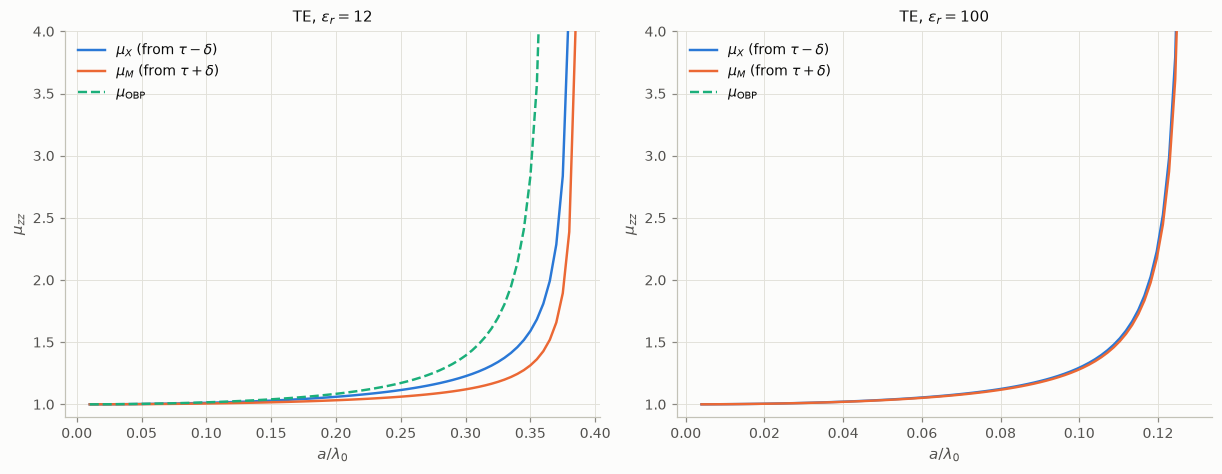

          f      mu_iso - 1   mu_X - 1    mu_M - 1    (mu_X - mu_M)/(mu_iso - 1)   mu_OBP - 1
eps_r=   12 0.0100     0.00009     0.00012     0.00006            0.571             0.00015
eps_r=   12 0.1350     0.01831     0.02368     0.01300            0.583             0.03157
eps_r=   12 0.2600     0.09957     0.13089     0.06994            0.612             0.19910
eps_r=   12 0.3850     5.80705    19.74553     3.07149            2.871            -2.29127
eps_r=  100 0.0040     0.00019     0.00020     0.00018            0.065             0.00020
eps_r=  100 0.0446     0.02657     0.02738     0.02575            0.061             0.02839
eps_r=  100 0.0869     0.15937     0.16345     0.15532            0.051             0.17336
eps_r=  100 0.1275    11.45351    12.62294    10.46898            0.188           155.88180
PASS  eps_r = 12, low frequency: the two apparent mu - 1 differ by more than half of mu - 1: got 0.571453, target 0.6, |diff| 2.85e-02 <= 2e-01
PASS  eps_r = 100, low fre


 eps_r   pole of mu from tau   pole of mu_OBP (zero of J0)   single-rod resonance
    12           0.3877                 0.3683                     0.3598
   100           0.1285                 0.1276                     0.1258
PASS  eps_r = 100: pole of mu within 1 percent of the O'Brien-Pendry pole: got 1.00727, target 1, |diff| 7.27e-03 <= 1e-02


In [6]:
def mu_obp(f, eps):
    x = TWO_PI * f * np.sqrt(eps) * R
    return 1 - FILL + FILL * 2 * jv(1, x) / (x * jv(0, x))


def mus(F, co):
    k2, t, d = (TWO_PI * F) ** 2, get(co, "tau"), get(co, "delta")
    return 1 / (1 - k2 * t), 1 / (1 - k2 * (t - d)), 1 / (1 - k2 * (t + d))


fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, F, co, eps in ((axs[0], F12, co12, 12.0), (axs[1], F100, co100, 100.0)):
    m_iso, m_X, m_M = mus(F, co)
    ax.plot(F, m_X, color=CAT[0], label=r"$\mu_X$ (from $\tau-\delta$)")
    ax.plot(F, m_M, color=CAT[1], label=r"$\mu_M$ (from $\tau+\delta$)")
    m_obp = mu_obp(F, eps)
    m_obp[np.argmax(m_obp < 1):] = np.nan if (m_obp < 1).any() else m_obp[-1]      # stop the curve at its pole
    ax.plot(F, m_obp, color=CAT[2], ls="--", label=r"$\mu_{\rm OBP}$")
    ax.set(xlabel=r"$a/\lambda_0$", ylabel=r"$\mu_{zz}$", ylim=(0.9, 4.0), title=rf"TE, $\varepsilon_r={eps:g}$"); ax.legend(loc="upper left")
plt.show()

print("          f      mu_iso - 1   mu_X - 1    mu_M - 1    (mu_X - mu_M)/(mu_iso - 1)   mu_OBP - 1")
aniso = {}
for F, co, eps in ((F12, co12, 12.0), (F100, co100, 100.0)):
    m_iso, m_X, m_M = mus(F, co)
    aniso[eps] = (m_X - m_M) / (m_iso - 1)
    for i in (0, len(F) // 3, 2 * len(F) // 3, len(F) - 1):
        print(f"eps_r={eps:5g} {F[i]:6.4f} {m_iso[i] - 1:11.5f} {m_X[i] - 1:11.5f} {m_M[i] - 1:11.5f} {aniso[eps][i]:16.3f} {mu_obp(F[i], eps) - 1:19.5f}")
check("eps_r = 12, low frequency: the two apparent mu - 1 differ by more than half of mu - 1", aniso[12.0][0], 0.2, 0.6)
check("eps_r = 100, low frequency: they differ by a few percent", aniso[100.0][0], 0.04, 0.065)


def tau_pole(eps, lo, hi):
    """Frequency at which k0^2 tau = 1 (mu_zz has its pole), by bisection."""
    g = lambda f: 1 - (TWO_PI * f) ** 2 * te_coefficients(f, eps, rho=0.1)["tau"]
    for _ in range(40):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if g(mid) > 0 else (lo, mid)
    return 0.5 * (lo + hi)


poles = {12.0: tau_pole(12.0, 0.36, 0.397), 100.0: tau_pole(100.0, 0.12, 0.134)}
print("\n eps_r   pole of mu from tau   pole of mu_OBP (zero of J0)   single-rod resonance")
for eps, lo_hi in ((12.0, (1.5, 2.6)), (100.0, (1.5, 2.6))):
    from scipy.optimize import brentq
    xres = brentq(lambda x: rl.mie_pq(np.array([0]), x / (np.sqrt(eps) * R), R, eps, "TE")[1][0], *lo_hi)
    print(f"{eps:6.0f} {poles[eps]:16.4f} {J0_ZERO / (TWO_PI * np.sqrt(eps) * R):22.4f} {xres / (TWO_PI * np.sqrt(eps) * R):26.4f}")
check("eps_r = 100: pole of mu within 1 percent of the O'Brien-Pendry pole", poles[100.0] / (J0_ZERO / (TWO_PI * 10 * R)), 0.01, 1.0)

For $\varepsilon_r=100$ the three curves are close: the permeability from $\tau$ has its pole within a percent of the O'Brien-Pendry one, and at low frequency the two apparent permeabilities differ by a few percent of $\mu-1$. For $\varepsilon_r=12$ the formula overestimates $\mu-1$ throughout and puts the pole too low, and far below resonance $\mu_X-1$ is nearly twice $\mu_M-1$: there is no single permeability at the level of the effect itself.

Toward the resonance the anisotropy shrinks relative to $\tau$ (the ratio $|\delta|/\tau$ falls, table of section 3), but it does not shrink in terms of $\mu$. The two apparent permeabilities have their poles at slightly different frequencies, and close to them they differ by any factor, as the last row for each permittivity shows. A resonant $\mu$ amplifies whatever small non-magnetic term it is combined with.

The O'Brien-Pendry formula and $\tau$ differ at low frequency for an identifiable reason: the formula counts the whole displacement current in the rod, $\varepsilon_r$ in place of $\varepsilon_r-1$, and it has no background term.

## 5. How far the second-order description reaches

The local model from the expansion is $\varepsilon_t(\omega)=\varepsilon^T(\omega,0)$ and one of the permeabilities above, with $k=k_0\sqrt{\varepsilon_t\mu}$. The exact Bloch wavenumber along a symmetry direction solves $k^2=k_0^2\varepsilon^T(\omega,k)$ with the full function; the cell does that by secant iteration and compares, on the first band. Three local variants are shown: no permeability, the isotropic one, and the one for the direction of propagation.

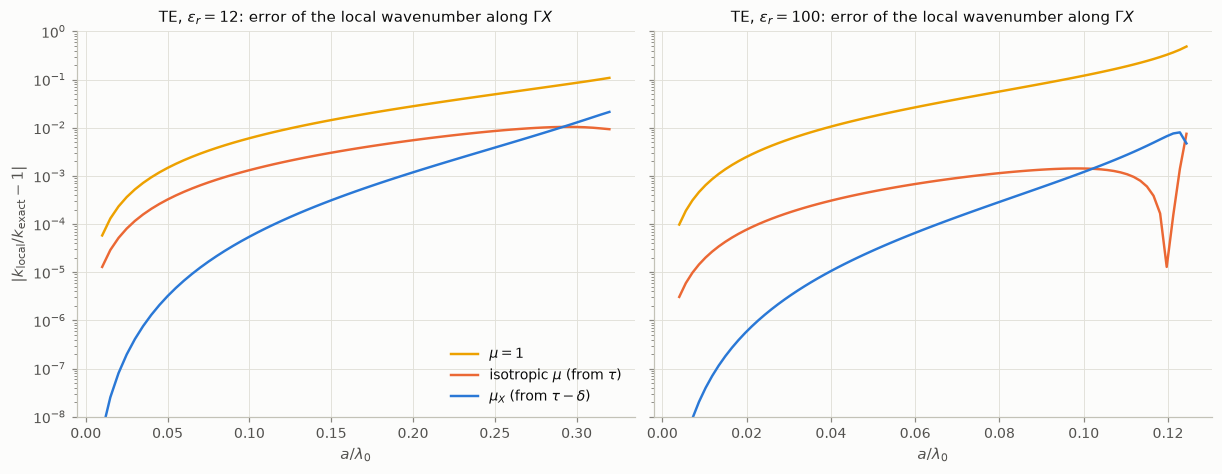

          f     k_exact a (GX)   error mu=1   error mu_iso   error mu_X    anisotropy (kM - kX)/kX: exact, from delta
eps_r=   12 0.0200       0.1605     -2.32e-04     -5.16e-05      8.05e-08          -1.03e-04  -1.03e-04
eps_r=   12 0.1650       1.3520     -1.78e-02     -3.68e-03      4.78e-04          -7.52e-03  -8.27e-03
eps_r=   12 0.3200       2.9216     -1.08e-01     -9.30e-03      2.13e-02          -9.93e-03  -5.73e-02
eps_r=  100 0.0071       0.0596     -3.10e-04     -9.76e-06      9.23e-09          -1.95e-05  -1.95e-05
eps_r=  100 0.0650       0.5613     -3.22e-02     -7.88e-04      9.66e-05          -1.73e-03  -1.77e-03
eps_r=  100 0.1244       2.0199     -4.84e-01     -7.48e-03      4.72e-03          -2.60e-03  -2.38e-02
PASS  eps_r = 12, low frequency: the index anisotropy between GM and GX is the one delta predicts (relative): got 0.996414, target 1, |diff| 3.59e-03 <= 2e-02
PASS  eps_r = 100: with mu_X the wavenumber is within 1 percent up to k a = 2: got 0.00799962, targ

In [7]:
def bloch_k(pol, k0, phi, eps, guess, M=4, tol=1e-12):
    """Bloch wavenumber along phi from k^2 = k0^2 eps_T(w, k), secant iteration from `guess` (complex allowed)."""
    g = lambda kap: k0**2 * eps_parts(pol, k0, kap, phi, eps, M)[0] - kap**2
    k1, k2 = guess, guess * 1.001 + 1e-4
    g1, g2 = g(k1), g(k2)
    for _ in range(60):
        k3 = k2 - g2 * (k2 - k1) / (g2 - g1)
        if abs(k3 - k2) < tol:
            return k3
        k1, g1, k2, g2 = k2, g2, k3, g(k3)
    return np.nan


def reach(F, co, eps, fmax):
    rows = []
    for f, c in zip(F, co):
        if f > fmax:
            break
        k0 = TWO_PI * f
        mu_iso, mu_X, mu_M = (1 / (1 - k0**2 * t) for t in (c["tau"], c["tau"] - c["delta"], c["tau"] + c["delta"]))
        kX = bloch_k("TE", k0, 0.0, eps, k0 * np.sqrt(c["eps"] * mu_X)).real
        kM = bloch_k("TE", k0, np.pi / 4, eps, k0 * np.sqrt(c["eps"] * mu_M)).real
        loc = lambda mu: k0 * np.sqrt(c["eps"] * mu)
        rows.append((f, kX, kM, loc(1.0), loc(mu_iso), loc(mu_X), loc(mu_M)))
    return np.array(rows)


rc12, rc100 = reach(F12, co12, 12.0, 0.32), reach(F100, co100, 100.0, 0.1255)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, rc, eps in ((axs[0], rc12, 12.0), (axs[1], rc100, 100.0)):
    f, kX = rc[:, 0], rc[:, 1]
    ax.semilogy(f, np.abs(rc[:, 3] / kX - 1), color=CAT[3], label=r"$\mu=1$")
    ax.semilogy(f, np.abs(rc[:, 4] / kX - 1), color=CAT[1], label=r"isotropic $\mu$ (from $\tau$)")
    ax.semilogy(f, np.abs(rc[:, 5] / kX - 1), color=CAT[0], label=r"$\mu_X$ (from $\tau-\delta$)")
    ax.set(xlabel=r"$a/\lambda_0$", title=rf"TE, $\varepsilon_r={eps:g}$: error of the local wavenumber along $\Gamma X$", ylim=(1e-8, 1))
axs[0].set_ylabel(r"$|k_{\rm local}/k_{\rm exact}-1|$"); axs[0].legend(loc="lower right")
plt.show()

print("          f     k_exact a (GX)   error mu=1   error mu_iso   error mu_X    anisotropy (kM - kX)/kX: exact, from delta")
for rc, eps in ((rc12, 12.0), (rc100, 100.0)):
    for i in (2, len(rc) // 2, len(rc) - 1):
        f, kX, kM, k1, kiso, kmx, kmm = rc[i]
        print(f"eps_r={eps:5g} {f:6.4f} {kX:12.4f} {k1 / kX - 1:13.2e} {kiso / kX - 1:13.2e} {kmx / kX - 1:13.2e} {kM / kX - 1:18.2e} {kmm / kmx - 1:10.2e}")
i = 5
check("eps_r = 12, low frequency: the index anisotropy between GM and GX is the one delta predicts (relative)",
      (rc12[i, 2] / rc12[i, 1] - 1) / (rc12[i, 6] / rc12[i, 5] - 1), 0.02, 1.0)
assert rc12[i, 2] < rc12[i, 1], "the wave along GM is slower in k than along GX at the same frequency"
check("eps_r = 100: with mu_X the wavenumber is within 1 percent up to k a = 2", np.abs(rc100[rc100[:, 1] < 2.0, 5] / rc100[rc100[:, 1] < 2.0, 1] - 1).max(), 0.01)
print(f"largest k_exact a covered: {rc12[-1, 1]:.2f} (eps_r = 12), {rc100[-1, 1]:.2f} (eps_r = 100)")

At low frequency the direction-specific permeability gives the wavenumber with an error that falls like the fourth power of frequency (the neglected $k^4$ terms), the isotropic one leaves the error of the anisotropy, which falls only like the second power, and no permeability at all is worse again. The difference between the wavenumbers along $\Gamma M$ and $\Gamma X$ at the same frequency is the one $\delta$ predicts. This is the lattice version of Lorentz's intrinsic birefringence: an index that depends on direction in a structure whose $\varepsilon$ and $\mu$ tensors are isotropic by symmetry.

Toward the resonance all local variants lose accuracy together, as the Bloch wavenumber grows and the fourth-order terms take over. For both permittivities the direction-specific model is within a percent up to $ka\approx2$ and reaches a few percent at the end of the range. The anisotropy fares worse: near the resonance the second-order prediction (last column) is several times larger than the exact one, because it comes from two permeabilities with different poles, while the exact wavenumbers along $\Gamma X$ and $\Gamma M$ stay within a percent of each other. The isotropic model, which ignores $\delta$, is then no worse than the direction-specific one.

## 6. TM: a second-order coefficient that vanishes, and a mode the permittivity does not see

For $\mathbf E$ along the rods the tensor has one component, and by notebook 01 its second-order coefficient $\beta$ is isotropic and always of the form of a permeability, $\mu_\parallel=1/(1-k_0^2\beta)$. Each rod has an in-plane magnetic-dipole moment, with the same loop estimate as in TE, $\beta_{\rm loop}=f(\varepsilon_r-1)R^2/8$.

In [8]:
def tm_coefficients(f, eps, rho=0.2):
    k0 = TWO_PI * f
    cX = taylor(lambda kap: eps_parts("TM", k0, kap, 0.0, eps), rho)[:, 0]
    cM = taylor(lambda kap: eps_parts("TM", k0, kap, np.pi / 4, eps), rho)[:, 0]
    return cX[0].real, cX[2].real, cM[2].real, cX[4].real, cM[4].real


FT = np.array([0.005, 0.01, 0.02, 0.04, 0.08, 0.12, 0.16, 0.20])
tm = np.array([tm_coefficients(f, 12.0) for f in FT])
beta_loop = FILL * 11.0 * R**2 / 8
print("TM, eps_r = 12:   f      eps_zz(w,0)     beta        beta / f^2    beta_GM - beta_GX    c4_GX       c4_GM")
for f, row in zip(FT, tm):
    print(f"              {f:6.3f} {row[0]:12.5f} {row[1]:12.3e} {row[1] / f**2:11.4f} {row[2] - row[1]:14.1e} {row[3]:14.3e} {row[4]:11.3e}")
print(f"loop estimate beta_loop = {beta_loop:.5f}")
check("beta is isotropic by symmetry (GM minus GX, largest)", np.abs(tm[:, 2] - tm[:, 1]).max(), 1e-9)
check("beta vanishes like f^2 at low frequency (exponent between f = 0.005 and 0.01)", np.log(tm[1, 1] / tm[0, 1]) / np.log(2), 0.05, 2.0)
check("at f = 0.01 beta is less than half a percent of the loop estimate", tm[1, 1] / beta_loop, 5e-3)
assert tm[-1, 3] != tm[-1, 4], "the fourth-order coefficient is not isotropic"

TM, eps_r = 12:   f      eps_zz(w,0)     beta        beta / f^2    beta_GM - beta_GX    c4_GX       c4_GM
               0.005      4.11061    1.006e-05      0.4025        4.2e-15      7.004e-07  -2.094e-07
               0.010      4.11191    4.033e-05      0.4033        2.4e-15      2.809e-06  -8.377e-07
               0.020      4.11712    1.625e-04      0.4063       -4.5e-14      1.134e-05  -3.353e-06
               0.040      4.13820    6.695e-04      0.4185        3.5e-14      4.717e-05  -1.344e-05
               0.080      4.22634    3.021e-03      0.4720        1.9e-13      2.213e-04  -5.350e-05
               0.120      4.38845    8.374e-03      0.5815        1.5e-13      6.592e-04  -1.111e-04
               0.160      4.65439    2.033e-02      0.7942       -6.8e-14      1.796e-03  -1.144e-04
               0.200      5.08686    4.941e-02      1.2352        6.7e-14      5.218e-03   3.885e-04
loop estimate beta_loop = 0.03499
PASS  beta is isotropic by symmetry (GM minus GX, la

The second-order coefficient is isotropic to rounding, as symmetry demands, and the fourth-order one is not. More striking, $\beta$ is not $\beta_{\rm loop}$ at low frequency: it goes to zero like $\omega^2$, so $\mu_\parallel-1$ is of order $\omega^4$ where the dipole estimate gives $\omega^2$. This is the cancellation of notebook 01, section 4, now for a strong rod. The field $E_z$ is not screened by the rod, so the loop current and the second-moment terms are driven by the same unscreened field and cancel, while in TE the screening of the dipolar field breaks the balance in favor of the loop. The magnetic-dipole radiation of the rod is real; in the bulk response it is not a permeability. In Landau and Lifshitz's terms this is a medium whose magnetization is not a meaningful quantity: the polarization current contributes to the moment of the cell as much as the loop does, at any rod permittivity.

Closer to the resonance the expansion in $k$ fails for a different reason. The cell below follows $\varepsilon_{zz}(\omega,0)$ and $\beta$ through the resonance region.

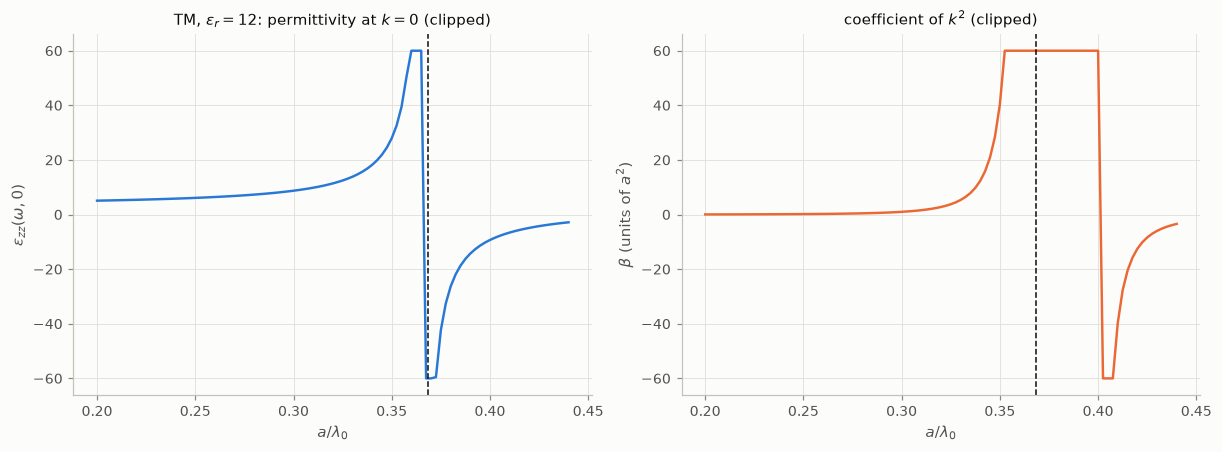

eps_zz(w, 0) changes sign through a pole between f = 0.3650 and 0.3675; zero of J0(k1 R) at 0.3683
beta on the two sides of the pole: 1173.9 and 1113.8 (same sign: a double pole)
PASS  the pole of eps_zz(w, 0) is within 1.5 percent of the zero of J0(k1 R): got 0.994457, target 1, |diff| 5.54e-03 <= 1e-02


In [9]:
FR = np.linspace(0.20, 0.44, 97)
tmr = np.array([tm_coefficients(f, 12.0, rho=0.05) for f in FR])
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(FR, np.clip(tmr[:, 0], -60, 60), color=CAT[0])
axs[0].set(xlabel=r"$a/\lambda_0$", ylabel=r"$\varepsilon_{zz}(\omega,0)$", title=r"TM, $\varepsilon_r=12$: permittivity at $k=0$ (clipped)")
axs[1].plot(FR, np.clip(tmr[:, 1], -60, 60), color=CAT[1])
axs[1].set(xlabel=r"$a/\lambda_0$", ylabel=r"$\beta$ (units of $a^2$)", title=r"coefficient of $k^2$ (clipped)")
for ax in axs:
    ax.axvline(J0_ZERO / (TWO_PI * np.sqrt(12.0) * R), color=INK, ls="--", lw=1)
plt.show()
i_pole = np.argmax(np.abs(np.diff(np.sign(tmr[:, 0]))) > 0)
f_pole = 0.5 * (FR[i_pole] + FR[i_pole + 1])
near = np.abs(FR - f_pole) < 0.03
print(f"eps_zz(w, 0) changes sign through a pole between f = {FR[i_pole]:.4f} and {FR[i_pole + 1]:.4f}; zero of J0(k1 R) at {J0_ZERO / (TWO_PI * np.sqrt(12.0) * R):.4f}")
print(f"beta on the two sides of the pole: {tmr[i_pole - 1, 1]:.1f} and {tmr[i_pole + 2, 1]:.1f} (same sign: a double pole)")
check("the pole of eps_zz(w, 0) is within 1.5 percent of the zero of J0(k1 R)", f_pole / (J0_ZERO / (TWO_PI * np.sqrt(12.0) * R)), 0.015, 1.0)
assert tmr[i_pole - 1, 1] > 20 and tmr[i_pole + 2, 1] > 20

$\varepsilon_{zz}(\omega,0)$ has a pole near the zero of $J_0(k_1R)$ (dashed), the frequency at which the field averaged over the cell vanishes while the polarization does not: an electric resonance, at almost the frequency of the magnetic-dipole resonance of the rod, which is the degeneracy of notebook 02 again. The position of this pole depends on $k$, so the coefficient of $k^2$ has a double pole at the same frequency, positive on both sides. No permeability behaves like that, and no expansion in $k$ at fixed frequency survives it. In this polarization the frequencies where the magnetic dipole of the rod is resonant are frequencies where the nonlocal permittivity is not expandable at all.

**A mode outside the description.** Check (c) found a TM Bloch mode that does not satisfy $k^2=k_0^2\varepsilon_{zz}$. The next cell lists the TM modes along $\Gamma X$ with their residual and the parity of their multipole coefficients under $y\to-y$.

In [10]:
def mode_parity(kB, f, eps, M=4):
    """Null vector b of I - T G at a mode, and the weight of its part that is odd under y -> -y."""
    Mm = rl.kkr_matrix(TWO_PI * f, kB, R, eps, "TM", M)
    b = np.linalg.svd(Mm)[2][-1].conj()
    l = np.arange(-M, M + 1)
    b_ref = (b * (-1.0) ** l)[::-1]                    # y -> -y maps b_l to (-1)^l b_{-l}
    odd = 0.5 * (b - b_ref)
    return np.linalg.norm(odd) ** 2 / np.linalg.norm(b) ** 2


print("TM, eps_r = 12, modes along GX:   k a       f        |k^2 - k0^2 eps_zz|     odd weight under y -> -y")
dark = []
for ka in (0.5, 1.0, 1.5, 2.0):
    for fm in rl.bloch_frequencies((ka, 0.0), R, 12.0, "TM", M=4, fmax=0.45, nscan=900):
        resid = abs((TWO_PI * fm) ** 2 * eps_parts("TM", TWO_PI * fm, ka, 0.0, 12.0)[0] - ka**2)
        odd = mode_parity((ka, 0.0), fm, 12.0)
        print(f"                                {ka:5.2f} {fm:9.5f} {resid:16.2e} {odd:22.6f}")
        if resid > 1e-3:
            dark.append((ka, fm, odd))
dark = np.array(dark)
check("every mode missed by eps_zz is odd under the mirror that contains k (smallest odd weight)", dark[:, 2].min(), 1e-8, 1.0)
print(f"frequency of the odd mode across the scanned k: {dark[:, 1].min():.4f} to {dark[:, 1].max():.4f}")
gamma_pair = rl.bloch_frequencies((1e-3, 0.0), R, 12.0, "TM", M=4, fmax=0.45, nscan=900)
print(f"modes at Gamma: {np.round(gamma_pair, 5)}")

TM, eps_r = 12, modes along GX:   k a       f        |k^2 - k0^2 eps_zz|     odd weight under y -> -y


                                 0.50   0.03912         1.29e-07               0.000000
                                 0.50   0.39523         1.02e-10               0.000000
                                 0.50   0.40191         5.39e+01               1.000000


                                 1.00   0.07746         9.33e-08               0.000000
                                 1.00   0.37920         1.38e-11               0.000000
                                 1.00   0.40291         5.21e+01               1.000000


                                 1.50   0.11409         1.17e-08               0.000000
                                 1.50   0.35811         6.49e-11               0.000000
                                 1.50   0.40433         4.91e+01               1.000000


                                 2.00   0.14766         4.03e-09               0.000000
                                 2.00   0.33531         1.07e-11               0.000000
                                 2.00   0.40584         4.51e+01               1.000000
PASS  every mode missed by eps_zz is odd under the mirror that contains k (smallest odd weight): got 1, target 1, |diff| 0.00e+00 <= 1e-08
frequency of the odd mode across the scanned k: 0.4019 to 0.4058


modes at Gamma: [0.40155 0.40155]


The modes that the permittivity misses along $\Gamma X$ are exactly the ones that are odd under the mirror containing $\mathbf k$ (the mode of check (c) along $\Gamma M$ is the same thing for the diagonal mirror). Their $E_z$ averages to zero over the cell with any weight $e^{-i\mathbf k\cdot\mathbf r}$ along the axis, so $\langle\mathbf E\rangle=\langle\mathbf P\rangle=0$ and, by Faraday's law, $\langle\mathbf B\rangle=0$: the mode carries no macroscopic $\mathbf E$ or $\mathbf B$ at all, and a $z$-directed source with this $\mathbf k$ cannot excite it. In the two-tensor language it is the **longitudinal magnetic mode**: a magnetization along $\mathbf k$, whose magnetization current $i\mathbf k\times\mathbf M$ vanishes, existing at the frequency where $\mu(\omega)=0$ with $\mathbf H=-\mathbf M\neq0$ and $\mathbf B=0$. At $\Gamma$ it is degenerate with the transverse mode, as the two components of one in-plane dipole must be. Away from $\Gamma$ the transverse mode moves down in frequency and this one moves up slightly, by about one percent over the scanned range, where a local $\mu(\omega)$ would give it no dispersion at all.

This is a limit of the single-tensor bookkeeping that is easy to overlook. $\varepsilon(\omega,\mathbf k)$ is a complete description of the response to currents and of the fields $\mathbf E$ and $\mathbf B$, and precisely for that reason it has no place for an excitation that produces neither. In three dimensions the same holds for longitudinal magnetic modes in general.

## Summary

- **Method.** The source-driven permittivity agrees with a plane-wave solution, with the static mixing formulas (Rayleigh's series to six digits in TE), and with the Bloch modes.
- **TE.** Of the three second-order coefficients only $\tau$ has the resonance pole, and only $\tau$ grows with the rod permittivity, with the current-loop slope $fR^2/8$ exactly. $\lambda$ and $\delta$ are a background of about $0.01\,a^2$ set mostly by the geometry. The permeability of the lattice is the part of the second-order spatial dispersion that escapes depolarization, and the Landau-Lifshitz ratio of that part to the rest is about 3 for $\varepsilon_r=12$ and 20 for $\varepsilon_r=100$ in the static limit.
- **One permeability or two.** Along $\Gamma X$ and $\Gamma M$ the apparent permeabilities differ by $\delta$. For $\varepsilon_r=100$ this is a few percent of $\mu-1$ at low frequency and less near resonance; for $\varepsilon_r=12$ it is more than half of $\mu-1$ at low frequency. The index anisotropy this implies is the one found in the exact Bloch wavenumbers.
- **Reach.** With the direction-specific permeability the error of the wavenumber falls like the fourth power of frequency; near the resonance every local variant fails together as $ka$ grows.
- **TM.** The second-order coefficient is isotropic by symmetry and vanishes at low frequency: the magnetic dipole of the rod is canceled in the bulk response. Near the rod resonance the permittivity has a $k$-dependent pole and no expansion. The longitudinal magnetic mode exists and is invisible to $\varepsilon(\omega,\mathbf k)$.

## Caveats and open ends

- The decomposition into loop and background in section 3 is identified by its dependence on the rod permittivity, not derived term by term; the multipole bookkeeping of notebook 01, section 4, was not carried out for the lattice.
- Coefficients are computed for lossless rods below the first diffraction threshold. With loss the same code runs (check (a) includes a lossy rod) but the coefficients become complex and were not studied.
- "Radius of convergence in $k$" is used loosely. The singularities of $\varepsilon(\omega,\cdot)$ in the complex $k$ plane were not located, only avoided, and the frequency ranges of section 3 stop short of the zero of $\mu$, where $\tau$ has a pole.
- The fourth-order coefficients are printed but not analyzed. They decide where the local model fails and how the failure depends on direction.

## References

- M. G. Silveirinha, Phys. Rev. B 75, 115104 (2007), source-driven homogenization.
- S. O'Brien and J. B. Pendry, J. Phys.: Condens. Matter 14, 4035 (2002).
- A. Alù, Phys. Rev. B 84, 075153 (2011); A. D. Yaghjian, A. Alù and M. G. Silveirinha, Photonics Nanostruct. Fundam. Appl. 11, 374 (2013).
- L. D. Landau, E. M. Lifshitz and L. P. Pitaevskii, *Electrodynamics of Continuous Media*, 2nd ed., sections 79 and 103.
- R. Merlin, Proc. Natl. Acad. Sci. USA 106, 1693 (2009).
- J. Skaar, H. O. Hågenvik and C. A. Dirdal, Phys. Rev. B 99, 064407 (2019).